# 02 · Image preprocessing, Dataset and DataLoader

**Goal:** turn MVTec AD images and masks into batched tensors that a PyTorch model can consume, and understand every step. No model is trained here.

Concepts covered: image tensors · channels and dimensions · resizing · value scaling · normalisation · `Dataset` · `DataLoader` and batching · avoiding train/test leakage.

In [1]:
import os
import sys
from pathlib import Path

# Make the repo importable whether the notebook is started from the repo root or notebooks/
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

DATA_ROOT = Path(os.environ.get("INSPECTAI_DATA_ROOT", REPO_ROOT / "data" / "mvtec_ad"))
if not DATA_ROOT.is_dir():
    raise FileNotFoundError(
        f"MVTec AD not found at {DATA_ROOT}. See docs/dataset.md for download and placement instructions, "
        "or set the INSPECTAI_DATA_ROOT environment variable."
    )
print("Data root:", DATA_ROOT)

import hashlib

import matplotlib.pyplot as plt
import numpy as np
import torch

from inspectai.device import select_device
from inspectai.data import index_category, load_image, load_mask
from inspectai.data.dataloader import build_dataloader, move_batch
from inspectai.data.dataset import MVTecDataset
from inspectai.data.stats import train_pixel_stats
from inspectai.data.transforms import (
    IMAGENET_MEAN, IMAGENET_STD, TRANSFORM_DOCS, build_image_transform, build_mask_transform, denormalize,
)
from inspectai.data.viz import plot_batch

CATEGORY = "bottle"      # change to "hazelnut" or "carpet"
IMAGE_SIZE = 256         # models get IMAGE_SIZE x IMAGE_SIZE inputs
print("torch", torch.__version__, "| category:", CATEGORY, "| image size:", IMAGE_SIZE)

Data root: ../data/mvtec_ad


torch 2.3.1 | category: bottle | image size: 256


## 1 · What is an image to a computer?

A colour image is a grid of pixels; each pixel has 3 numbers (**channels**): red, green, blue, each an 8-bit integer 0–255. Different libraries order the dimensions differently:

| Library | Layout | Name | Typical dtype / range |
|---|---|---|---|
| Pillow → NumPy | `(H, W, C)` | channels-last | `uint8`, 0–255 |
| PyTorch models | `(C, H, W)` | channels-first | `float32`, ~0–1 or normalised |
| A batch for PyTorch | `(B, C, H, W)` | batch of images | `float32` |

Pillow reports size as `(width, height)`; arrays use `(height, width)`.

PIL size (W, H): (900, 900) | mode: RGB
NumPy shape (H, W, C): (900, 900, 3) | dtype: uint8 | min/max: 29 255


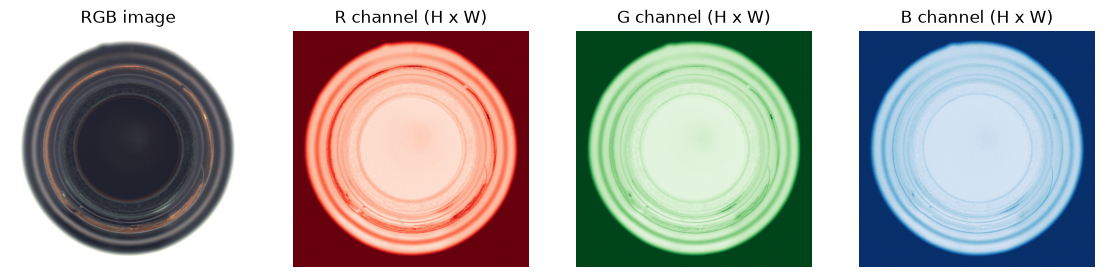

In [2]:
sample = index_category(DATA_ROOT, CATEGORY, "train")[0]
pil = load_image(sample.image_path)           # in-memory copy, file untouched
arr = np.asarray(pil)

print("PIL size (W, H):", pil.size, "| mode:", pil.mode)
print("NumPy shape (H, W, C):", arr.shape, "| dtype:", arr.dtype, "| min/max:", arr.min(), arr.max())

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
axes[0].imshow(arr); axes[0].set_title("RGB image")
for i, (name, cmap) in enumerate([("R", "Reds"), ("G", "Greens"), ("B", "Blues")], start=1):
    axes[i].imshow(arr[..., i - 1], cmap=cmap, vmin=0, vmax=255); axes[i].set_title(f"{name} channel (H x W)")
for a in axes: a.axis("off")
plt.show()

## 2 · Resizing

Networks need a fixed input size, and the originals are large. We resize to `IMAGE_SIZE x IMAGE_SIZE` with **bilinear interpolation + antialiasing** (smooth, avoids aliasing when shrinking).

For **masks** we use **nearest-neighbour** instead. Interpolating a 0/255 mask would invent in-between values at the edges that are neither normal nor defective:

original mask values  : [  0 255]
bilinear resized      : 230 distinct values  <- invented grey levels
nearest resized       : [  0 255]  <- still binary


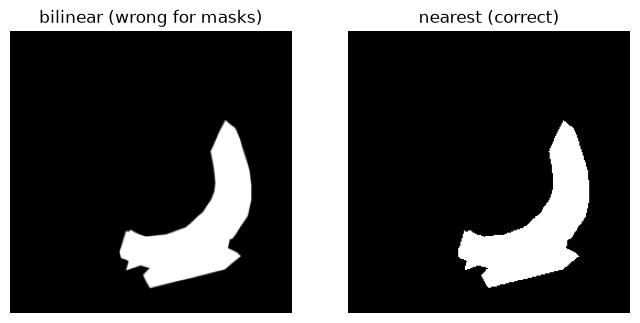

In [3]:
from torchvision.transforms import InterpolationMode, v2

defect = next(s for s in index_category(DATA_ROOT, CATEGORY, "test") if s.is_defective)
mask_pil = load_mask(defect.mask_path)
small = (IMAGE_SIZE, IMAGE_SIZE)

bilinear = np.asarray(v2.Resize(small, interpolation=InterpolationMode.BILINEAR)(mask_pil))
nearest = np.asarray(v2.Resize(small, interpolation=InterpolationMode.NEAREST)(mask_pil))
print("original mask values  :", np.unique(np.asarray(mask_pil)))
print("bilinear resized      :", len(np.unique(bilinear)), "distinct values  <- invented grey levels")
print("nearest resized       :", np.unique(nearest), " <- still binary")

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(bilinear, cmap="gray"); axes[0].set_title("bilinear (wrong for masks)")
axes[1].imshow(nearest, cmap="gray"); axes[1].set_title("nearest (correct)")
for a in axes: a.axis("off")
plt.show()

## 3 · From PIL image to tensor

`ToImage` + `ToDtype(float32, scale=True)` does three things at once:

1. `(H, W, C)` → `(C, H, W)` (channels-first)
2. `uint8` → `float32`
3. scales values from 0–255 down to **0.0–1.0**

In [4]:
plain = build_image_transform(IMAGE_SIZE, normalize=False)(pil)
print("shape:", tuple(plain.shape), "| dtype:", plain.dtype)
print("min/max:", plain.min().item(), plain.max().item())
print("per-channel mean:", plain.mean(dim=(1, 2)))

shape: (3, 256, 256) | dtype: torch.float32
min/max: 0.12156863510608673 1.0
per-channel mean: tensor([0.5334, 0.5296, 0.5472])


## 4 · Normalisation

Normalisation standardises each channel: 

$$x_{norm} = \frac{x - \text{mean}_c}{\text{std}_c}$$

so inputs are centred near 0 with a spread near 1, which makes optimisation better behaved. Two sensible choices:

* **ImageNet statistics** (`IMAGENET_MEAN/STD`). Required when using a backbone pretrained on ImageNet, which is the likely route in later stages.
* **Dataset statistics**, computed from **training images only**. Computing them over test images would leak test information into preprocessing.

Below we compute the training-set statistics for this category and compare.

In [5]:
train_samples = index_category(DATA_ROOT, CATEGORY, "train")
ds_stats = train_pixel_stats(train_samples)   # train/good only
print("train-set mean:", ds_stats["mean"], "| std:", ds_stats["std"], f"({ds_stats['n_images']} images)")
print("ImageNet  mean:", IMAGENET_MEAN, "| std:", IMAGENET_STD)

train-set mean: [0.53541, 0.53168, 0.54796] | std: [0.36676, 0.36667, 0.34992] (209 images)
ImageNet  mean: (0.485, 0.456, 0.406) | std: (0.229, 0.224, 0.225)


normalised: min -1.59  max 2.64  per-channel mean [0.21 0.33 0.63]


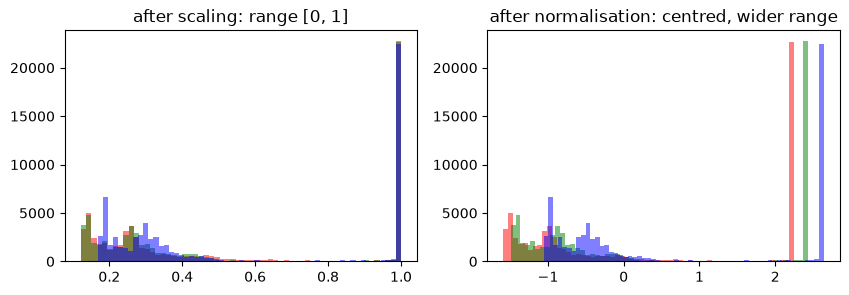

max round-trip error: 5.960464477539063e-08


In [6]:
norm = build_image_transform(IMAGE_SIZE)(pil)          # ImageNet normalisation
print("normalised: min %.2f  max %.2f  per-channel mean %s" % (norm.min(), norm.max(), norm.mean(dim=(1, 2)).numpy().round(2)))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for c, col in enumerate("rgb"):
    axes[0].hist(plain[c].flatten().numpy(), bins=60, color=col, alpha=0.5)
    axes[1].hist(norm[c].flatten().numpy(), bins=60, color=col, alpha=0.5)
axes[0].set_title("after scaling: range [0, 1]"); axes[1].set_title("after normalisation: centred, wider range")
plt.show()

# Normalisation is reversible (needed for display)
restored = denormalize(norm)
print("max round-trip error:", (restored - plain).abs().max().item())

## 5 · The full pipeline, documented

`build_image_transform` and `build_mask_transform` chain the steps above. The original files are never modified; every step operates on an in-memory copy.

In [7]:
for kind, steps in TRANSFORM_DOCS.items():
    print(f"{kind} pipeline:")
    for i, step in enumerate(steps, 1):
        print(f"  {i}. {step}")
print()
print(build_image_transform(IMAGE_SIZE))
print(build_mask_transform(IMAGE_SIZE))

image pipeline:
  1. Resize to (image_size, image_size), bilinear interpolation with antialiasing
  2. ToImage + ToDtype(float32, scale=True): PIL HxWxC uint8 [0,255] -> torch CxHxW float32 [0,1]
  3. Normalize: (x - mean) / std per channel (default: ImageNet statistics)
mask pipeline:
  1. Resize to (image_size, image_size), nearest-neighbour (keeps labels binary)
  2. Binarize: any pixel > 0 becomes 1.0, else 0.0
  3. Output: 1xHxW float32 with values in {0, 1}

Compose(
      Resize(size=[256, 256], interpolation=InterpolationMode.BILINEAR, antialias=True)
      ToImage()
      ToDtype(scale=True)
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], inplace=False)
      ToPureTensor()
)
Compose(
      Resize(size=[256, 256], interpolation=InterpolationMode.NEAREST, antialias=True)
      Binarize()
)


## 6 · `Dataset`: one sample at a time

A PyTorch `Dataset` answers two questions: **how many samples?** (`__len__`) and **give me sample *i*** (`__getitem__`). Ours loads the image and mask lazily from disk on each access (memory use stays tiny) and applies the transforms.

Each sample is a dictionary, and the **image-level label and the pixel-level mask are separate entries**:

| key | shape / type | meaning |
|---|---|---|
| `image` | `(3, H, W)` float32 | preprocessed image |
| `label` | scalar int64 | image-level: 0 normal, 1 defective |
| `mask` | `(1, H, W)` float32 in {0, 1} | pixel-level ground truth (all zeros for normal) |
| `defect_type` | str | `good` or the defect name |
| `path` | str | source file |

In [8]:
train_ds = MVTecDataset(DATA_ROOT, CATEGORY, "train", image_size=IMAGE_SIZE, verify_images=True)  # decodes every image once
test_ds = MVTecDataset(DATA_ROOT, CATEGORY, "test", image_size=IMAGE_SIZE, verify_images=True)
print(train_ds)
print(test_ds)

idx = next(i for i, s in enumerate(test_ds.samples) if s.is_defective)
item = test_ds[idx]
for k, v in item.items():
    print(f"{k:<12}", tuple(v.shape) if hasattr(v, "shape") else v, getattr(v, "dtype", ""))

MVTecDataset(category='bottle', split='train', n=209, normal=209, defective=0)
MVTecDataset(category='bottle', split='test', n=83, normal=20, defective=63)
image        (3, 256, 256) torch.float32
label        () torch.int64
mask         (1, 256, 256) torch.float32
defect_type  broken_large 
path         ../data/mvtec_ad/bottle/test/broken_large/000.png 


## 7 · `DataLoader`: batching, shuffling, workers

A `DataLoader` repeatedly draws sample indices, calls `dataset[i]` for each, and **collates** the results into a batch by stacking tensors along a new first dimension: `N` items of `(3, H, W)` become one `(N, 3, H, W)` tensor. Strings are gathered into a list.

* `shuffle=True` for training (different order each epoch); `False` for evaluation. We seed the shuffle for reproducibility.
* `num_workers=0` loads in the main process. That is a good default on macOS; more workers can speed up large datasets.
* The final batch may be smaller unless `drop_last=True`.

In [9]:
train_loader = build_dataloader(train_ds, batch_size=16, seed=0)
test_loader = build_dataloader(test_ds, batch_size=16)

batch = next(iter(train_loader))
for k, v in batch.items():
    print(f"{k:<12}", tuple(v.shape) if hasattr(v, "shape") else f"list[{len(v)}] e.g. {v[0]!r}"[:70])

print("\nbatches per epoch  train:", len(train_loader), " test:", len(test_loader))
print("train batch sizes:", [b["image"].shape[0] for b in train_loader])

image        (16, 3, 256, 256)
label        (16,)
mask         (16, 1, 256, 256)
defect_type  list[16] e.g. 'good'
path         list[16] e.g. '../data/mvtec_ad/bottle/train/good/133.png'

batches per epoch  train: 14  test: 6


train batch sizes: [16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 1]


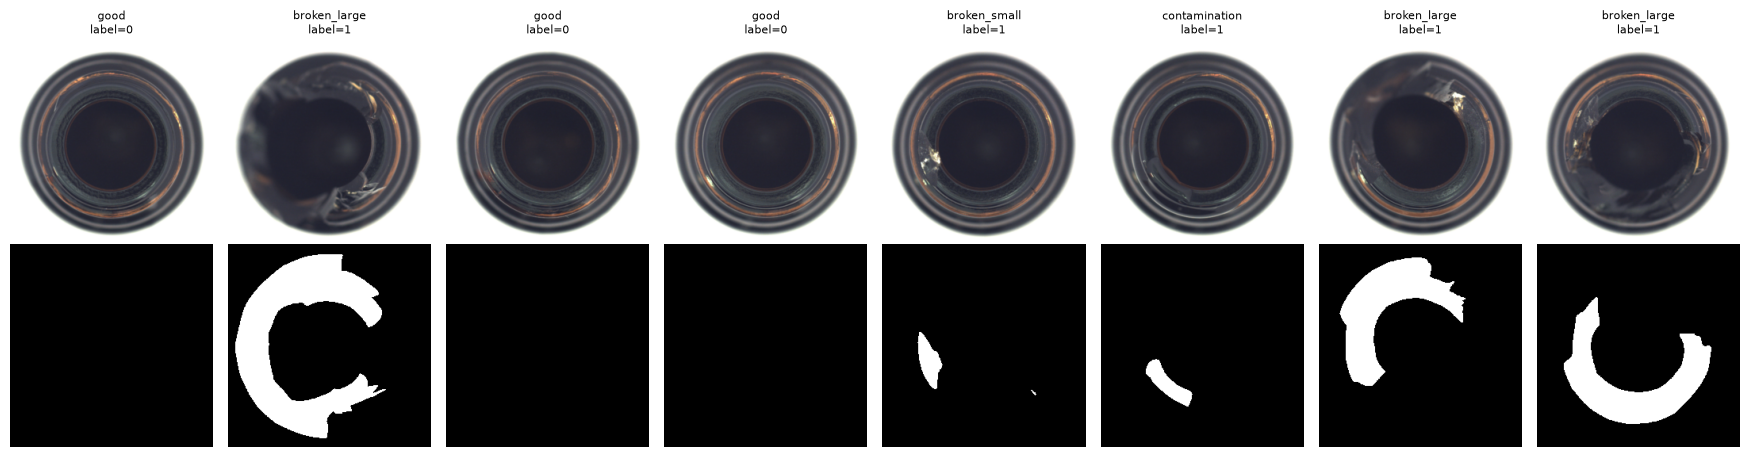

In [10]:
test_batch = next(iter(build_dataloader(test_ds, batch_size=8, shuffle=True, seed=1)))
plot_batch(test_batch, n=8)
plt.show()

## 8 · Leakage and integrity checks

Anomaly detection is evaluated on defects the model has never seen, so we verify programmatically that:

1. the training dataset contains only normal images and no mask is ever non-empty;
2. no file appears in both train and test;
3. normalisation statistics were computed from training images only (section 4);
4. iterating the whole dataset leaves the original files byte-for-byte unchanged.

In [11]:
train_paths = {s.image_path for s in train_ds.samples}
test_paths = {s.image_path for s in test_ds.samples}

assert train_ds.num_defective == 0 and all(l == 0 for l in train_ds.labels), "defect in train split!"
assert not (train_paths & test_paths), "train/test overlap!"
assert all(p.parent.parent.name == "train" for p in train_paths)
assert all(p.parent.parent.name == "test" for p in test_paths)
print("1-3. split integrity: OK  (train", len(train_paths), "files, test", len(test_paths), "files, overlap 0)")

def digest(paths):
    return {p: hashlib.sha256(p.read_bytes()).hexdigest() for p in paths}

all_files = sorted((DATA_ROOT / CATEGORY).rglob("*.png"))
before = digest(all_files)
for loader in (train_loader, test_loader):
    for _ in loader:
        pass
assert before == digest(all_files), "a source file changed!"
print(f"4. originals unchanged after a full pass over train and test: OK ({len(all_files)} files hashed)")

# image-level label and mask agree but are separate
for i in range(len(test_ds)):
    it = test_ds[i]
    assert (it["label"].item() == 1) == (it["mask"].sum().item() > 0)
print("   image-level labels consistent with pixel-level masks: OK")

1-3. split integrity: OK  (train 209 files, test 83 files, overlap 0)


4. originals unchanged after a full pass over train and test: OK (355 files hashed)


   image-level labels consistent with pixel-level masks: OK


## 9 · Moving batches to the compute device

Batches are created on the CPU. To use the Apple GPU we move the tensors with `.to("mps")`; strings stay on the host. `pin_memory` is only enabled for CUDA, since it does nothing for MPS.

In [12]:
device = select_device("auto")
gpu_batch = move_batch(batch, device)
print("device:", device, "| image tensor on:", gpu_batch["image"].device, "| paths remain:", type(gpu_batch["path"]).__name__)

device: cpu | image tensor on: cpu | paths remain: list


## Summary of transformations applied

| Step | Image | Mask |
|---|---|---|
| Load | Pillow, converted to RGB (copy in memory) | Pillow, single channel `L` |
| Resize | `IMAGE_SIZE x IMAGE_SIZE`, bilinear + antialias | same size, nearest-neighbour |
| Scale | `uint8` 0–255 → `float32` 0–1, `(H,W,C)` → `(C,H,W)` | `> 0` → `{0.0, 1.0}`, shape `(1,H,W)` |
| Normalise | `(x − mean) / std`, ImageNet statistics by default | none |

No augmentation is applied. Original files are never modified. Stage 2 can build on this loader.